#statistics for machine learning's project
This notebook builds the final implicit-feedback dataset used in the recommender-system models.

## 1. Configuration

Edit only `PROJECT_DIR` if the project folder changes. The notebook expects the raw Shopify/Matrixify files in `raw_data`.

In [1]:
from pathlib import Path
import re
import shutil
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_DIR = Path(
    r"C:/Users/matia/OneDrive/Desktop/Data Science Master/2.- SECOND SEMESTER/4.- BRUTTI STAT/final_project"
)

RAW_DATA_DIR = PROJECT_DIR / "raw_data"
PROCESSED_DATA_DIR = PROJECT_DIR / "processed_data_final"
OUTPUT_FILE = PROCESSED_DATA_DIR / "interactions_real_long.csv"

PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Raw data directory:", RAW_DATA_DIR)
print("Single output file:", OUTPUT_FILE)

Project directory: C:\Users\matia\OneDrive\Desktop\Data Science Master\2.- SECOND SEMESTER\4.- BRUTTI STAT\final_project
Raw data directory: C:\Users\matia\OneDrive\Desktop\Data Science Master\2.- SECOND SEMESTER\4.- BRUTTI STAT\final_project\raw_data
Single output file: C:\Users\matia\OneDrive\Desktop\Data Science Master\2.- SECOND SEMESTER\4.- BRUTTI STAT\final_project\processed_data_final\interactions_real_long.csv


## 2. Load Shopify sales exports

We load only the columns required to construct customer--item interactions.

In [2]:
SALES_FILES = sorted(RAW_DATA_DIR.glob("Sales_until_*.xlsx"))

if not SALES_FILES:
    raise FileNotFoundError(f"No Sales_until_*.xlsx files found in {RAW_DATA_DIR}")

SALES_COLUMNS = [
    "ID",
    "Processed At",
    "Cancelled At",
    "Payment: Status",
    "Order Fulfillment Status",
    "Customer: ID",
    "Line: Type",
    "Line: ID",
    "Line: Product ID",
    "Line: Variant ID",
    "Line: SKU",
    "Line: Quantity",
    "Line: Total",
]

IDENTIFIER_COLUMNS = {
    "ID": "string",
    "Customer: ID": "string",
    "Line: ID": "string",
    "Line: Product ID": "string",
    "Line: Variant ID": "string",
    "Line: SKU": "string",
}


def parse_datetime_utc(series: pd.Series) -> pd.Series:
    try:
        return pd.to_datetime(series, errors="coerce", utc=True, format="mixed")
    except TypeError:
        return pd.to_datetime(series, errors="coerce", utc=True)


def load_sales_file(file_path: Path) -> pd.DataFrame:
    df = pd.read_excel(
        file_path,
        sheet_name="Orders",
        usecols=lambda column: column in SALES_COLUMNS,
        dtype=IDENTIFIER_COLUMNS,
        engine="openpyxl",
    )

    df["source_file"] = file_path.name

    for column in ["Processed At", "Cancelled At"]:
        df[column] = parse_datetime_utc(df[column])

    for column in ["Line: Quantity", "Line: Total"]:
        df[column] = pd.to_numeric(df[column], errors="coerce")

    # Matrixify usually stores the order ID and order-level fields only on the first row of each order.
    df["order_id"] = df["ID"].ffill()

    order_level_columns = [
        "Processed At",
        "Cancelled At",
        "Payment: Status",
        "Order Fulfillment Status",
        "Customer: ID",
    ]

    for column in order_level_columns:
        df[f"{column}_order"] = df.groupby("order_id", sort=False, dropna=False)[column].transform("first")

    return df

sales_by_file = {}
for file_path in SALES_FILES:
    print(f"Reading {file_path.name}...")
    sales_by_file[file_path.name] = load_sales_file(file_path)
    print(f"  rows: {len(sales_by_file[file_path.name]):,}")

print(f"\nLoaded {len(SALES_FILES)} sales export(s).")

Reading Sales_until_20210601.xlsx...
  rows: 97,201
Reading Sales_until_20221002.xlsx...
  rows: 104,265
Reading Sales_until_20240721.xlsx...
  rows: 87,367
Reading Sales_until_20251230.xlsx...
  rows: 65,249

Loaded 4 sales export(s).


## 3. Combine exports and keep the newest snapshot per order

If an order appears in more than one exported file, we keep the version coming from the most recent snapshot. This avoids duplicated purchases across export boundaries.

In [3]:
def extract_snapshot_date(file_name: str) -> pd.Timestamp:
    match = re.search(r"(\d{8})", file_name)
    if match is None:
        return pd.NaT
    return pd.to_datetime(match.group(1), format="%Y%m%d", errors="coerce")

sales_combined = pd.concat(sales_by_file.values(), ignore_index=True)
sales_combined["snapshot_date"] = sales_combined["source_file"].apply(extract_snapshot_date)
sales_combined = sales_combined.dropna(subset=["order_id"]).copy()

order_sources = sales_combined[["order_id", "source_file", "snapshot_date"]].drop_duplicates()

preferred_order_source = (
    order_sources
    .sort_values(["order_id", "snapshot_date", "source_file"])
    .drop_duplicates(subset=["order_id"], keep="last")
    .rename(columns={"source_file": "preferred_source_file"})
)

sales_master_rows = sales_combined.merge(
    preferred_order_source[["order_id", "preferred_source_file"]],
    on="order_id",
    how="inner",
    validate="many_to_one",
)

sales_master_rows = sales_master_rows.loc[
    sales_master_rows["source_file"].eq(sales_master_rows["preferred_source_file"])
].copy()

sum_orders_by_file = sum(df["order_id"].nunique() for df in sales_by_file.values())
unique_orders_all_files = sales_combined["order_id"].nunique()
duplicated_order_occurrences = sum_orders_by_file - unique_orders_all_files

print("Order occurrences across files:", f"{sum_orders_by_file:,}")
print("Unique orders after combining:", f"{unique_orders_all_files:,}")
print("Duplicated order occurrences removed:", f"{duplicated_order_occurrences:,}")
print("Rows retained after snapshot deduplication:", f"{len(sales_master_rows):,}")

Order occurrences across files: 40,008
Unique orders after combining: 39,899
Duplicated order occurrences removed: 109
Rows retained after snapshot deduplication: 352,673


## 4. Keep valid completed orders

We retain only orders that are paid, not cancelled, processed, and fulfilled. This makes the positive interactions correspond to purchases that were actually completed from the customer perspective.

In [13]:
orders_master = (
    sales_master_rows[[
        "order_id",
        "Processed At_order",
        "Cancelled At_order",
        "Payment: Status_order",
        "Order Fulfillment Status_order",
        "Customer: ID_order",
        "source_file",
        "snapshot_date",
    ]]
    .drop_duplicates(subset=["order_id"], keep="last")
    .rename(columns={
        "Processed At_order": "processed_at",
        "Cancelled At_order": "cancelled_at",
        "Payment: Status_order": "payment_status",
        "Order Fulfillment Status_order": "fulfillment_status",
        "Customer: ID_order": "customer_id",
    })
    .copy()
)

orders_master["payment_status"] = orders_master["payment_status"].astype("string").str.strip().str.lower()
orders_master["fulfillment_status"] = orders_master["fulfillment_status"].astype("string").str.strip().str.lower()

print("Payment status counts:")
display(orders_master["payment_status"].value_counts(dropna=False).to_frame("orders"))

print("Fulfillment status counts:")
display(orders_master["fulfillment_status"].value_counts(dropna=False).to_frame("orders"))

completed_orders = orders_master.loc[
    orders_master["payment_status"].eq("paid")
    & orders_master["cancelled_at"].isna()
    & orders_master["processed_at"].notna()
    & orders_master["customer_id"].notna()
].copy()

print("All unique orders:", f"{len(orders_master):,}")
print("Completed fulfilled orders with customer ID:", f"{len(completed_orders):,}")
print("Unique identified customers:", f"{completed_orders['customer_id'].nunique():,}")
print("Date range:", completed_orders["processed_at"].min(), "to", completed_orders["processed_at"].max())

Payment status counts:


,orders
payment_status,
paid,39506
voided,231
refunded,59
partially_refunded,52
pending,44
partially_paid,5
<NA>,2


Fulfillment status counts:


,orders
fulfillment_status,
fulfilled,33713
<NA>,6171
restocked,11
partial,4


All unique orders: 39,899
Completed fulfilled orders with customer ID: 39,425
Unique identified customers: 23,605
Date range: 2019-10-17 15:21:16+00:00 to 2025-12-30 23:51:15+00:00


## 5. Keep only purchased product lines

We keep only `Line Item` rows with positive quantity and a product, variant, or SKU identifier. Shipping lines, transaction rows, fulfillment rows, discounts, and other non-product rows are excluded.

In [14]:
line_items = sales_master_rows.loc[sales_master_rows["Line: Type"].eq("Line Item")].copy()

line_items["quantity"] = pd.to_numeric(line_items["Line: Quantity"], errors="coerce")
line_items["line_total"] = pd.to_numeric(line_items["Line: Total"], errors="coerce")

line_items_with_id = (
    line_items.loc[line_items["Line: ID"].notna()]
    .sort_values("snapshot_date")
    .drop_duplicates(subset=["order_id", "Line: ID"], keep="last")
)

line_items_without_id = line_items.loc[line_items["Line: ID"].isna()].copy()
line_items_master = pd.concat([line_items_with_id, line_items_without_id], ignore_index=True)

completed_order_ids = set(completed_orders["order_id"])

completed_line_items = line_items_master.loc[
    line_items_master["order_id"].isin(completed_order_ids)
    & line_items_master["quantity"].gt(0)
    & (
        line_items_master["Line: Product ID"].notna()
        | line_items_master["Line: Variant ID"].notna()
        | line_items_master["Line: SKU"].notna()
    )
].copy()

completed_line_items = completed_line_items.drop(columns=["Customer: ID_order"], errors="ignore")

completed_line_items = completed_line_items.merge(
    completed_orders[["order_id", "customer_id", "processed_at"]],
    on="order_id",
    how="left",
    validate="many_to_one",
)

completed_line_items = completed_line_items.rename(columns={
    "Line: Product ID": "product_id",
    "Line: Variant ID": "variant_id",
    "Line: SKU": "sku",
})

for column in ["product_id", "variant_id", "sku"]:
    completed_line_items[column] = completed_line_items[column].astype("string").str.strip()

completed_line_items["item_id"] = pd.Series(pd.NA, index=completed_line_items.index, dtype="string")

product_mask = completed_line_items["product_id"].notna() & completed_line_items["product_id"].ne("")
variant_mask = completed_line_items["item_id"].isna() & completed_line_items["variant_id"].notna() & completed_line_items["variant_id"].ne("")
sku_mask = completed_line_items["item_id"].isna() & completed_line_items["sku"].notna() & completed_line_items["sku"].ne("")

completed_line_items.loc[product_mask, "item_id"] = "product_" + completed_line_items.loc[product_mask, "product_id"]
completed_line_items.loc[variant_mask, "item_id"] = "variant_" + completed_line_items.loc[variant_mask, "variant_id"]
completed_line_items.loc[sku_mask, "item_id"] = "sku_" + completed_line_items.loc[sku_mask, "sku"]

completed_line_items = completed_line_items.dropna(subset=["item_id"]).copy()

print("Completed product lines:", f"{len(completed_line_items):,}")
print("Total purchased units:", f"{completed_line_items['quantity'].sum():,.0f}")
print("Unique raw item IDs:", f"{completed_line_items['item_id'].nunique():,}")

Completed product lines: 139,293
Total purchased units: 150,234
Unique raw item IDs: 4,409


## 6. ISBN cleaning utilities

ISBN-10 codes are converted to ISBN-13 by adding the 978 prefix and recomputing the check digit. This avoids treating ISBN-10 and ISBN-13 representations of the same book as different items.

In [15]:
def normalize_identifier_text(value) -> str:
    if pd.isna(value):
        return ""
    text = str(value).strip().upper()
    if text.endswith(".0"):
        text = text[:-2]
    return re.sub(r"[^0-9X]", "", text)


def is_valid_isbn10(value: str) -> bool:
    value = normalize_identifier_text(value)
    if not re.fullmatch(r"\d{9}[\dX]", value):
        return False
    digits = [10 if character == "X" else int(character) for character in value]
    return sum(weight * digit for weight, digit in zip(range(10, 0, -1), digits)) % 11 == 0


def is_valid_isbn13(value: str) -> bool:
    value = normalize_identifier_text(value)
    if not re.fullmatch(r"\d{13}", value):
        return False
    if not value.startswith(("978", "979")):
        return False
    weighted_sum = sum((1 if position % 2 == 0 else 3) * int(character) for position, character in enumerate(value[:12]))
    expected_check_digit = (10 - weighted_sum % 10) % 10
    return expected_check_digit == int(value[-1])


def isbn10_to_isbn13(value: str):
    value = normalize_identifier_text(value)
    if not is_valid_isbn10(value):
        return pd.NA
    body = "978" + value[:9]
    weighted_sum = sum((1 if position % 2 == 0 else 3) * int(character) for position, character in enumerate(body))
    check_digit = (10 - weighted_sum % 10) % 10
    return body + str(check_digit)


def canonical_isbn13(value):
    value = normalize_identifier_text(value)
    if is_valid_isbn13(value):
        return value
    if is_valid_isbn10(value):
        return isbn10_to_isbn13(value)
    return pd.NA


def split_identifier_list(value):
    if pd.isna(value):
        return []
    return [token.strip() for token in re.split(r"[|;,]", str(value)) if token.strip()]


def first_unique_isbn13(values):
    isbns = []
    for value in values:
        for token in split_identifier_list(value):
            isbn = canonical_isbn13(token)
            if pd.notna(isbn):
                isbns.append(str(isbn))
    isbns = sorted(set(isbns))
    return isbns[0] if len(isbns) == 1 else pd.NA

# Directly extract ISBN information from the sales SKU when possible.
completed_line_items["line_isbn13"] = completed_line_items["sku"].apply(canonical_isbn13)

isbn_audit = pd.DataFrame({
    "metric": [
        "Product lines with valid ISBN in Line: SKU",
        "Product lines without valid ISBN in Line: SKU",
        "Unique ISBN-13 values from Line: SKU",
    ],
    "value": [
        completed_line_items["line_isbn13"].notna().sum(),
        completed_line_items["line_isbn13"].isna().sum(),
        completed_line_items["line_isbn13"].nunique(),
    ],
})

display(isbn_audit)

,metric,value
0,Product lines with valid ISBN in Line: SKU,137019
1,Product lines without valid ISBN in Line: SKU,2274
2,Unique ISBN-13 values from Line: SKU,4235


## 7. Optional catalogue metadata

If `Product.xlsx` exists, the notebook uses product, variant, SKU, and barcode information to resolve item identities more accurately. If it does not exist, the pipeline still works using line-level identifiers.

In [16]:
PRODUCT_FILE = RAW_DATA_DIR / "Product.xlsx"

PRODUCT_COLUMNS = [
    "ID",
    "Title",
    "Vendor",
    "Type",
    "Tags",
    "Status",
    "Published",
    "Category: Name",
    "Category",
    "Variant ID",
    "Variant SKU",
    "Variant Barcode",
    "Variant Price",
]


def join_unique_strings(series: pd.Series) -> str:
    values = series.astype("string").dropna().str.strip()
    values = values.loc[values.ne("")].unique()
    return " | ".join(sorted(map(str, values)))

products_raw = pd.DataFrame()
products_clean = pd.DataFrame()

if PRODUCT_FILE.exists():
    products_raw = pd.read_excel(
        PRODUCT_FILE,
        sheet_name="Products",
        usecols=lambda column: column in PRODUCT_COLUMNS,
        dtype={
            "ID": "string",
            "Variant ID": "string",
            "Variant SKU": "string",
            "Variant Barcode": "string",
        },
        engine="openpyxl",
    )

    for column in PRODUCT_COLUMNS:
        if column not in products_raw.columns:
            products_raw[column] = pd.NA

    products_raw["Variant Price"] = pd.to_numeric(products_raw["Variant Price"], errors="coerce")
    products_raw["product_id"] = products_raw["ID"].ffill().astype("string").str.strip()
    products_raw = products_raw.dropna(subset=["product_id"]).copy()

    for column in ["Title", "Vendor", "Type", "Tags", "Status", "Published", "Category: Name", "Category"]:
        products_raw[column] = products_raw.groupby("product_id", sort=False)[column].transform("first")

    products_clean = (
        products_raw
        .groupby("product_id", as_index=False)
        .agg(
            title=("Title", "first"),
            vendor=("Vendor", "first"),
            product_type=("Type", "first"),
            tags=("Tags", "first"),
            status=("Status", "first"),
            published=("Published", "first"),
            category_name=("Category: Name", "first"),
            category=("Category", "first"),
            variant_count=("Variant ID", "nunique"),
            variant_skus=("Variant SKU", join_unique_strings),
            variant_barcodes=("Variant Barcode", join_unique_strings),
            minimum_variant_price=("Variant Price", "min"),
            maximum_variant_price=("Variant Price", "max"),
        )
    )

    products_clean["resolved_item_id"] = "product_" + products_clean["product_id"].astype("string")
    products_clean["catalogue_isbn13"] = products_clean.apply(
        lambda row: first_unique_isbn13([row["variant_barcodes"], row["variant_skus"]]),
        axis=1,
    )

    print("Catalogue products loaded:", f"{len(products_clean):,}")
    print("Catalogue products with one canonical ISBN-13:", f"{products_clean['catalogue_isbn13'].notna().sum():,}")
else:
    print("Product.xlsx not found. Continuing without catalogue metadata.")

Catalogue products loaded: 5,698
Catalogue products with one canonical ISBN-13: 5,519


## 8. Create anonymous IDs and build clean purchase records

Customer and order identifiers are replaced by sequential anonymous IDs. The mapping tables are kept only in memory and are not exported.

In [17]:
def create_sequential_mapping(values, original_column: str, anonymous_column: str, prefix: str) -> pd.DataFrame:
    unique_values = pd.Series(values, dtype="string").dropna().str.strip()
    unique_values = unique_values.loc[unique_values.ne("")]
    unique_values = pd.Series(unique_values.unique(), dtype="string").sort_values().reset_index(drop=True)
    width = max(6, len(str(len(unique_values))))
    anonymous_values = [f"{prefix}_{number:0{width}d}" for number in range(1, len(unique_values) + 1)]
    return pd.DataFrame({original_column: unique_values, anonymous_column: anonymous_values})

customer_mapping = create_sequential_mapping(
    values=completed_orders["customer_id"],
    original_column="customer_id",
    anonymous_column="customer_id_anon",
    prefix="customer",
)

order_mapping = create_sequential_mapping(
    values=completed_orders["order_id"],
    original_column="order_id",
    anonymous_column="order_id_anon",
    prefix="order",
)

purchases_clean = (
    completed_line_items[[
        "order_id",
        "customer_id",
        "processed_at",
        "item_id",
        "product_id",
        "variant_id",
        "sku",
        "line_isbn13",
        "quantity",
        "line_total",
    ]]
    .dropna(subset=["order_id", "customer_id", "processed_at", "item_id"])
    .merge(customer_mapping, on="customer_id", how="left", validate="many_to_one")
    .merge(order_mapping, on="order_id", how="left", validate="many_to_one")
)

purchases_clean = (
    purchases_clean
    .groupby([
        "order_id_anon",
        "customer_id_anon",
        "processed_at",
        "item_id",
        "product_id",
        "variant_id",
        "sku",
        "line_isbn13",
    ], as_index=False, dropna=False)
    .agg(
        quantity=("quantity", "sum"),
        line_total=("line_total", lambda values: values.sum(min_count=1)),
    )
    .sort_values(["processed_at", "order_id_anon", "item_id"])
    .reset_index(drop=True)
)

print("Anonymous customers:", f"{len(customer_mapping):,}")
print("Anonymous orders:", f"{len(order_mapping):,}")
print("Clean purchase lines:", f"{len(purchases_clean):,}")

Anonymous customers: 23,605
Anonymous orders: 39,425
Clean purchase lines: 139,073


## 9. Resolve each purchased item to a modelling `work_id`

Priority used to define the canonical recommendation item:

1. ISBN extracted directly from the sales line SKU;
2. manual reviewed mapping, when available;
3. catalogue ISBN from product metadata, when uniquely defined;
4. fallback raw product/variant/SKU identifier.

In [20]:
purchase_item_ids = purchases_clean[["item_id"]].drop_duplicates().rename(columns={"item_id": "source_item_id"}).copy()
purchase_item_ids["resolved_item_id"] = purchase_item_ids["source_item_id"]

variant_to_product = {}
sku_to_product = {}

if not products_raw.empty:
    catalogue_variants = products_raw[["product_id", "Variant ID", "Variant SKU"]].copy()
    catalogue_variants["product_item_id"] = "product_" + catalogue_variants["product_id"].astype("string").str.strip()

    for column in ["Variant ID", "Variant SKU"]:
        catalogue_variants[column] = catalogue_variants[column].astype("string").str.strip()

    valid_variant_rows = catalogue_variants.loc[catalogue_variants["Variant ID"].notna() & catalogue_variants["Variant ID"].ne("")].copy()
    variant_counts = valid_variant_rows.groupby("Variant ID")["product_item_id"].nunique()
    unique_variants = set(variant_counts[variant_counts.eq(1)].index)
    variant_to_product = (
        valid_variant_rows.loc[valid_variant_rows["Variant ID"].isin(unique_variants)]
        .drop_duplicates("Variant ID")
        .set_index("Variant ID")["product_item_id"]
        .to_dict()
    )

    valid_sku_rows = catalogue_variants.loc[catalogue_variants["Variant SKU"].notna() & catalogue_variants["Variant SKU"].ne("")].copy()
    sku_counts = valid_sku_rows.groupby("Variant SKU")["product_item_id"].nunique()
    unique_skus = set(sku_counts[sku_counts.eq(1)].index)
    sku_to_product = (
        valid_sku_rows.loc[valid_sku_rows["Variant SKU"].isin(unique_skus)]
        .drop_duplicates("Variant SKU")
        .set_index("Variant SKU")["product_item_id"]
        .to_dict()
    )

variant_mask = purchase_item_ids["source_item_id"].str.startswith("variant_", na=False)
variant_values = purchase_item_ids.loc[variant_mask, "source_item_id"].str.removeprefix("variant_")
purchase_item_ids.loc[variant_mask, "resolved_item_id"] = variant_values.map(variant_to_product).fillna(purchase_item_ids.loc[variant_mask, "source_item_id"])

sku_mask = purchase_item_ids["source_item_id"].str.startswith("sku_", na=False)
sku_values = purchase_item_ids.loc[sku_mask, "source_item_id"].str.removeprefix("sku_")
purchase_item_ids.loc[sku_mask, "resolved_item_id"] = sku_values.map(sku_to_product).fillna(purchase_item_ids.loc[sku_mask, "source_item_id"])

catalogue_isbn_map = pd.DataFrame(columns=["resolved_item_id", "catalogue_isbn13"])
if not products_clean.empty:
    catalogue_isbn_map = products_clean[["resolved_item_id", "catalogue_isbn13"]].drop_duplicates()

item_identity_map = purchase_item_ids.merge(
    catalogue_isbn_map,
    on="resolved_item_id",
    how="left",
    validate="many_to_one",
)

MANUAL_WORK_MAP_FILE = RAW_DATA_DIR / "manual_work_map.csv"
manual_work_map = pd.DataFrame(columns=["resolved_item_id", "manual_work_id"])

if MANUAL_WORK_MAP_FILE.exists():
    manual_work_map = pd.read_csv(MANUAL_WORK_MAP_FILE, dtype="string")
    required_columns = {"resolved_item_id", "work_id"}
    missing_columns = required_columns - set(manual_work_map.columns)
    if missing_columns:
        raise ValueError("manual_work_map.csv is missing columns: " + ", ".join(sorted(missing_columns)))
    manual_work_map = (
        manual_work_map[["resolved_item_id", "work_id"]]
        .dropna()
        .rename(columns={"work_id": "manual_work_id"})
        .drop_duplicates()
    )

    conflicts = manual_work_map.groupby("resolved_item_id")["manual_work_id"].nunique()
    if conflicts.gt(1).any():
        raise ValueError("At least one resolved_item_id has multiple manual work IDs.")

item_identity_map = item_identity_map.merge(
    manual_work_map,
    on="resolved_item_id",
    how="left",
    validate="many_to_one",
)

purchases_by_work = purchases_clean.rename(columns={"item_id": "source_item_id"}).merge(
    item_identity_map,
    on="source_item_id",
    how="left",
    validate="many_to_one",
)

purchases_by_work["automatic_work_id"] = purchases_by_work["resolved_item_id"].astype("string")

catalogue_mask = purchases_by_work["catalogue_isbn13"].notna()
purchases_by_work.loc[catalogue_mask, "automatic_work_id"] = (
    "work_isbn13_"
    + purchases_by_work.loc[catalogue_mask, "catalogue_isbn13"].astype("string")
)

purchases_by_work["work_id"] = (
    purchases_by_work["manual_work_id"]
    .fillna(purchases_by_work["automatic_work_id"])
    .astype("string")
)

if purchases_by_work["work_id"].isna().any():
    raise ValueError("At least one purchase could not be assigned to a work_id.")

identity_audit = pd.DataFrame({
    "metric": [
        "Raw purchased item IDs",
        "Resolved item IDs",
        "Lines using ISBN from sales SKU",
        "Lines using manual mapping",
        "Lines using catalogue ISBN",
        "Lines using fallback product/variant/SKU ID",
        "Final work IDs",
    ],
    "value": [
        item_identity_map["source_item_id"].nunique(),
        item_identity_map["resolved_item_id"].nunique(),
        line_isbn_mask.sum(),
        manual_mask.sum(),
        catalogue_mask.sum(),
        fallback_mask.sum(),
        purchases_by_work["work_id"].nunique(),
    ],
})

display(identity_audit)

,metric,value
0,Raw purchased item IDs,4409
1,Resolved item IDs,4408
2,Lines using ISBN from sales SKU,136805
3,Lines using manual mapping,0
4,Lines using catalogue ISBN,134577
5,Lines using fallback product/variant/SKU ID,2267
6,Final work IDs,4405


## 10. Build the final customer--work interaction table

The final dataset is binary implicit feedback: each row is one observed customer--work pair. Quantity, spend, and repeated orders are retained only as auxiliary variables.

In [21]:
observed_interactions_long = (
    purchases_by_work
    .groupby(["customer_id_anon", "work_id"], as_index=False, dropna=False)
    .agg(
        distinct_orders=("order_id_anon", "nunique"),
        units=("quantity", "sum"),
        total_spend=("line_total", lambda values: values.sum(min_count=1)),
        first_purchase=("processed_at", "min"),
        last_purchase=("processed_at", "max"),
    )
)

observed_interactions_long["binary_utility"] = np.float32(1.0)
observed_interactions_long["repeat_purchase_utility"] = np.log2(
    1 + observed_interactions_long["distinct_orders"].clip(lower=1)
).astype(np.float32)

# These columns are kept for compatibility with model notebooks that expect the previous schema.
observed_interactions_long["interaction_source"] = "observed"
observed_interactions_long["simulation_rule"] = pd.Series(pd.NA, index=observed_interactions_long.index, dtype="string")
observed_interactions_long["simulation_seed"] = pd.Series(pd.NA, index=observed_interactions_long.index, dtype="Int64")
observed_interactions_long["simulation_score"] = np.nan

observed_interactions_long = observed_interactions_long.sort_values(
    ["customer_id_anon", "work_id"]
).reset_index(drop=True)

n_users = observed_interactions_long["customer_id_anon"].nunique()
n_items = observed_interactions_long["work_id"].nunique()
n_interactions = len(observed_interactions_long)
density = n_interactions / (n_users * n_items)
sparsity = 1 - density

summary_table = pd.DataFrame({
    "metric": [
        "Users",
        "Items / works",
        "Positive user-item interactions",
        "Density (%)",
        "Sparsity (%)",
        "Total units purchased",
        "Interactions with units > 1 (%)",
        "Repeated user-item pairs (%)",
    ],
    "value": [
        n_users,
        n_items,
        n_interactions,
        100 * density,
        100 * sparsity,
        observed_interactions_long["units"].sum(),
        100 * observed_interactions_long["units"].gt(1).mean(),
        100 * observed_interactions_long["distinct_orders"].gt(1).mean(),
    ],
})

display(summary_table)
display(observed_interactions_long.head())

,metric,value
0,Users,23605.000000
1,Items / works,4405.000000
2,Positive user-item interactions,136832.000000
3,Density (%),0.131595
4,Sparsity (%),99.868405
5,Total units purchased,150234.000000
6,Interactions with units > 1 (%),5.461442
7,Repeated user-item pairs (%),1.483571


,customer_id_anon,work_id,distinct_orders,units,total_spend,first_purchase,last_purchase,binary_utility,repeat_purchase_utility,interaction_source,simulation_rule,simulation_seed,simulation_score
0,customer_000001,work_isbn13_9786071608062,1,1.0,19990.0,2019-10-17 15:21:16+00:00,2019-10-17 15:21:16+00:00,1.0,1.0,observed,<NA>,<NA>,NaN
1,customer_000002,product_4358886621265,1,1.0,3500.0,2020-01-09 19:06:21+00:00,2020-01-09 19:06:21+00:00,1.0,1.0,observed,<NA>,<NA>,NaN
2,customer_000002,work_isbn13_9786071600677,1,1.0,12720.0,2020-01-23 15:59:36+00:00,2020-01-23 15:59:36+00:00,1.0,1.0,observed,<NA>,<NA>,NaN
3,customer_000002,work_isbn13_9786071657114,1,1.0,9520.0,2020-01-23 16:03:53+00:00,2020-01-23 16:03:53+00:00,1.0,1.0,observed,<NA>,<NA>,NaN
4,customer_000003,work_isbn13_9786071635372,1,1.0,17430.0,2020-04-20 17:33:17+00:00,2020-04-20 17:33:17+00:00,1.0,1.0,observed,<NA>,<NA>,NaN


## 11. Descriptive plots for the report

These plots are displayed in the notebook only. They are not saved as files.

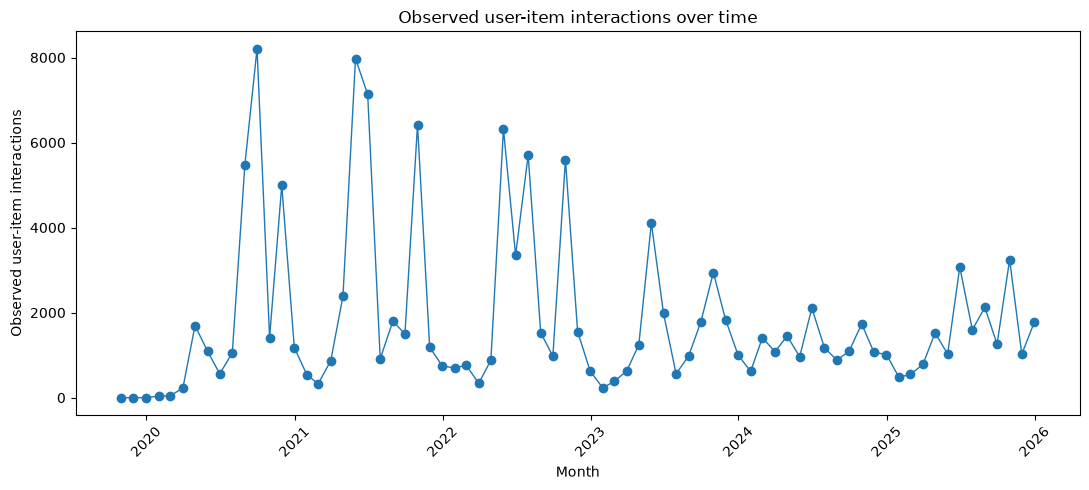

,interactions_per_user
count,23605.000000
mean,5.796738
std,10.616117
min,1.000000
25%,1.000000
50%,3.000000
75%,6.000000
90%,13.000000
95%,21.000000
99%,47.000000


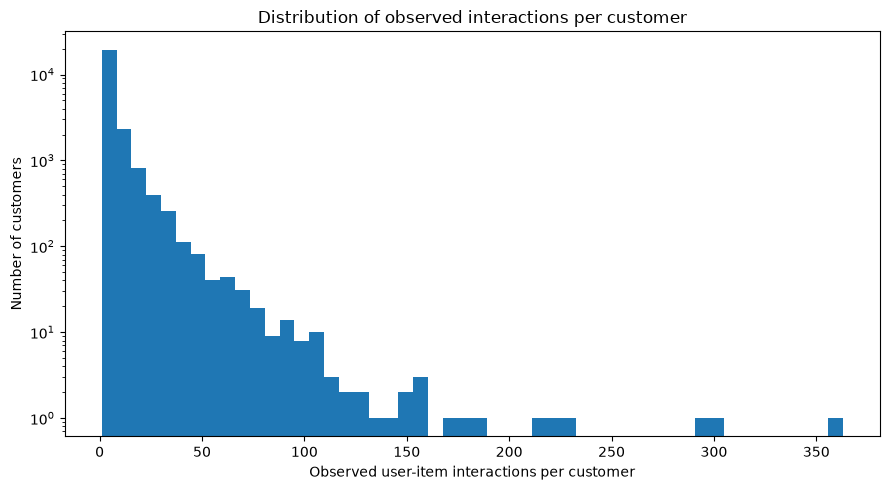

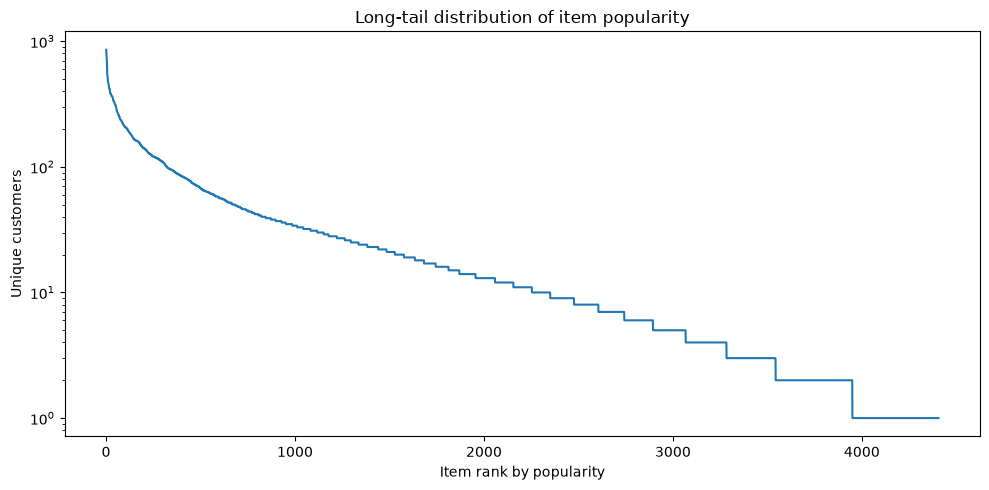

,min_interactions,users,items,positive_interactions,density_pct,sparsity_pct
0,3,11878,4319,121671,0.237170,99.762830
1,5,7802,4268,107815,0.323779,99.676221
2,10,3665,4101,80536,0.535829,99.464171
3,20,1313,3793,49226,0.988432,99.011568
4,25,916,3684,40601,1.203155,98.796845


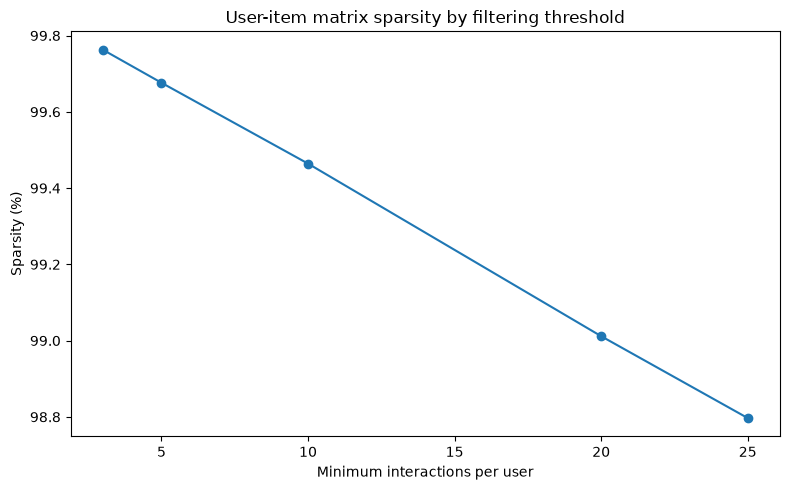

In [22]:
# Monthly interactions over time
monthly_interactions = (
    observed_interactions_long.dropna(subset=["first_purchase"])
    .set_index("first_purchase")
    .resample("ME")
    .size()
    .rename("interactions")
    .reset_index()
)

plt.figure(figsize=(11, 5))
plt.plot(monthly_interactions["first_purchase"], monthly_interactions["interactions"], marker="o", linewidth=1)
plt.xlabel("Month")
plt.ylabel("Observed user-item interactions")
plt.title("Observed user-item interactions over time")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Interactions per customer
interactions_per_user = observed_interactions_long.groupby("customer_id_anon").size()

display(interactions_per_user.describe(percentiles=[0.25, 0.5, 0.75, 0.90, 0.95, 0.99]).to_frame("interactions_per_user"))

plt.figure(figsize=(9, 5))
plt.hist(interactions_per_user, bins=50)
plt.xlabel("Observed user-item interactions per customer")
plt.ylabel("Number of customers")
plt.title("Distribution of observed interactions per customer")
plt.yscale("log")
plt.tight_layout()
plt.show()

# Item popularity long tail
users_per_item = observed_interactions_long.groupby("work_id")["customer_id_anon"].nunique()
item_popularity = users_per_item.sort_values(ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 5))
plt.plot(np.arange(1, len(item_popularity) + 1), item_popularity.values)
plt.xlabel("Item rank by popularity")
plt.ylabel("Unique customers")
plt.title("Long-tail distribution of item popularity")
plt.yscale("log")
plt.tight_layout()
plt.show()

# Sparsity by minimum interactions threshold
thresholds = [3, 5, 10, 20, 25]
rows = []

for threshold in thresholds:
    user_counts = observed_interactions_long.groupby("customer_id_anon")["work_id"].transform("size")
    filtered = observed_interactions_long.loc[user_counts >= threshold].copy()

    n_users_t = filtered["customer_id_anon"].nunique()
    n_items_t = filtered["work_id"].nunique()
    n_interactions_t = len(filtered)
    density_t = n_interactions_t / (n_users_t * n_items_t)

    rows.append({
        "min_interactions": threshold,
        "users": n_users_t,
        "items": n_items_t,
        "positive_interactions": n_interactions_t,
        "density_pct": 100 * density_t,
        "sparsity_pct": 100 * (1 - density_t),
    })

sparsity_table = pd.DataFrame(rows)
display(sparsity_table)

plt.figure(figsize=(8, 5))
plt.plot(sparsity_table["min_interactions"], sparsity_table["sparsity_pct"], marker="o")
plt.xlabel("Minimum interactions per user")
plt.ylabel("Sparsity (%)")
plt.title("User-item matrix sparsity by filtering threshold")
plt.tight_layout()
plt.show()

## 12. Export the only file used by the modelling notebooks

In [23]:
observed_interactions_long.to_csv(OUTPUT_FILE, index=False, encoding="utf-8-sig")

print("Saved only:", OUTPUT_FILE)
print("Rows:", f"{len(observed_interactions_long):,}")
print("Users:", f"{observed_interactions_long['customer_id_anon'].nunique():,}")
print("Items:", f"{observed_interactions_long['work_id'].nunique():,}")

Saved only: C:\Users\matia\OneDrive\Desktop\Data Science Master\2.- SECOND SEMESTER\4.- BRUTTI STAT\final_project\processed_data_final\interactions_real_long.csv
Rows: 136,832
Users: 23,605
Items: 4,405
